<a href="https://colab.research.google.com/github/LSDtopotools/lsdtt_notebooks/blob/master/lsdtopotools/examples_for_ppl_who_asked/data_download_and_viz_for_cholponbek.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A notebook to process topographic data without API authentication

Simon M Mudd 04/02/2026

This allows users to download topographic data and look at a nice hillshade without using authentication. It uses the Microsoft planetary-computer interface for this purpose. It downloads COP-30 topographic data and projects it into UTM

## Install the required packages.

First we install a few python packages for downloading an visualising data. This took 8 seconds the last time I tried.

In [ ]:
!pip -q install pystac-client planetary-computer rasterio lsdviztools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.3/278.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.5/208.5 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 52.7 MB/s eta 0:00:00


## Now install some command line tools, gdal and lsdtopotools

Install the lsdtopotools command line tools (took 41 seconds the last time I tried)

In [ ]:
!wget https://www.geos.ed.ac.uk/~smudd/lsdtt_dev_ubuntu/lsdtopotools_0.10~d1-1_amd64.deb  &> /dev/null
!apt install ./lsdtopotools_0.10~d1-1_amd64.deb  &> /dev/null

Now install gdal command line tools (this took 14 seconds the last time I tried).

In [ ]:
!apt install gdal-bin  &> /dev/null

## Select your study area

You should select the lower left and upper right corners of your study area. The easiest way to do this is to go on Google maps and right click these locations. A right click will copy the lat-long coordinates in the correct format.

In [16]:
# --- input: lower-left and upper-right as (lat, lon) ---
ll_lat, ll_lon = 42.76339080381686, 76.75470190244536
ur_lat, ur_lon = 43.38702755283246, 78.10038382903613

## Download data from your study area using `planetary_computer`

We use `planetary_computer` since you do not need to authenticate to download data.

In [18]:
from pystac_client import Client
import planetary_computer as pc
import rasterio
from rasterio.merge import merge
from rasterio.warp import transform_bounds
import numpy as np


# Convert to STAC bbox format: [min_lon, min_lat, max_lon, max_lat]
bbox = [min(ll_lon, ur_lon), min(ll_lat, ur_lat), max(ll_lon, ur_lon), max(ll_lat, ur_lat)]

# --- STAC search on Planetary Computer ---
stac = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

search = stac.search(
    collections=["cop-dem-glo-30"],  # Copernicus DEM GLO-30
    bbox=bbox,
)

items = list(search.items())
if not items:
    raise RuntimeError("No Copernicus DEM items found for that bounding box.")

# Sign items so the asset URLs are downloadable (adds SAS tokens)
items = [pc.sign(item) for item in items]

# Helper: get the main DEM GeoTIFF asset key robustly
def get_dem_asset(item):
    if "data" in item.assets:
        return item.assets["data"]
    # fallback: first GeoTIFF-like asset
    for k, a in item.assets.items():
        mt = (a.media_type or "").lower()
        if "geotiff" in mt or (a.href.lower().endswith((".tif", ".tiff"))):
            return a
    raise KeyError("Couldn't find a DEM GeoTIFF asset on the item.")

asset_hrefs = [get_dem_asset(it).href for it in items]

# --- Read, mosaic (if needed), and crop to your bbox ---
srcs = [rasterio.open(href) for href in asset_hrefs]
try:
    # Bounds must be in the dataset CRS for rasterio.merge.merge(bounds=...)
    dst_bounds = transform_bounds("EPSG:4326", srcs[0].crs, *bbox, densify_pts=21)

    mosaic, transform = merge(srcs, bounds=dst_bounds)

    # Convert nodata if needed (optional)
    nodata = srcs[0].nodata
    if nodata is None:
        nodata = -9999

    out_meta = srcs[0].meta.copy()
    out_meta.update(
        driver="GTiff",
        height=mosaic.shape[1],
        width=mosaic.shape[2],
        transform=transform,
        nodata=nodata,
    )

    out_path = "copernicus_dem_glo30_clip.tif"
    with rasterio.open(out_path, "w", **out_meta) as dst:
        dst.write(mosaic)

finally:
    for s in srcs:
        s.close()

out_path


'copernicus_dem_glo30_clip.tif'

## Now convert to UTM

We use gdal to convert to UTM. You need to know the UTM zone and enter it below. I like this website to look up the UTM zone: https://www.dmap.co.uk/utmworld.htm

In [21]:
!gdalwarp -t_srs '+proj=utm +zone=43 +datum=WGS84' -overwrite -r cubic -tr 30 30 -of ENVI copernicus_dem_glo30_clip.tif copernicus_dem_glo30_clip.bil

Creating output file that is 3718P x 2414L.
Processing copernicus_dem_glo30_clip.tif [1/1] : 0Using internal nodata values (e.g. -9999) for image copernicus_dem_glo30_clip.tif.
Copying nodata values from source copernicus_dem_glo30_clip.tif to destination copernicus_dem_glo30_clip.bil.
...10...20...30...40...50...60...70...80...90...100 - done.


# Look at your data using lsdtt

In [11]:
import lsdviztools.lsdmapwrappers as lsdmw

In [22]:
r_prefix = "copernicus_dem_glo30_clip"
w_prefix = "copernicus_dem_glo30_clip"
lsdtt_parameters = {"write_hillshade" : "true"}
lsdtt_drive = lsdmw.lsdtt_driver(read_prefix = r_prefix,
                                 write_prefix= w_prefix,
                                 read_path = "./",
                                 write_path = "./",
                                 parameter_dictionary=lsdtt_parameters)
lsdtt_drive.print_parameters()
lsdtt_drive.run_lsdtt_command_line_tool()

The lsdtopotools command line tools available are: 
['lsdtt-basic-metrics', 'lsdtt-channel-extraction', 'lsdtt-chi-mapping', 'lsdtt-cosmo-tool', 'lsdtt-hillslope-channel-coupling', 'lsdtt-valley-metrics', 'lsdtt-basin-metrics']
Testing has been done against lsdtopotools v0.7
The command line tool is: lsdtt-basic-metrics
The driver name is: Test_01
The read path is: ./
The write path is: ./
The read prefix is: copernicus_dem_glo30_clip
The write prefix is: copernicus_dem_glo30_clip
The parameter dictionary is:
{'write_hillshade': 'true'}
Done writing the driver file
I've finished writing the driver file. Let me run LSDTT for you.


Have a look at the data

In [23]:
%%capture
# Use the capture comment to get rid of all the text
# But it will also not display an inline image
# So you need to call the image from the next line of code
Base_file = r_prefix
DataDirectory = "./"
this_img = lsdmw.SimpleHillshade(DataDirectory,Base_file,cmap="gist_earth",
                                 save_fig=True, size_format="geomorphology",dpi=400)

./copernicus_dem_glo30_clip_hillshade.png


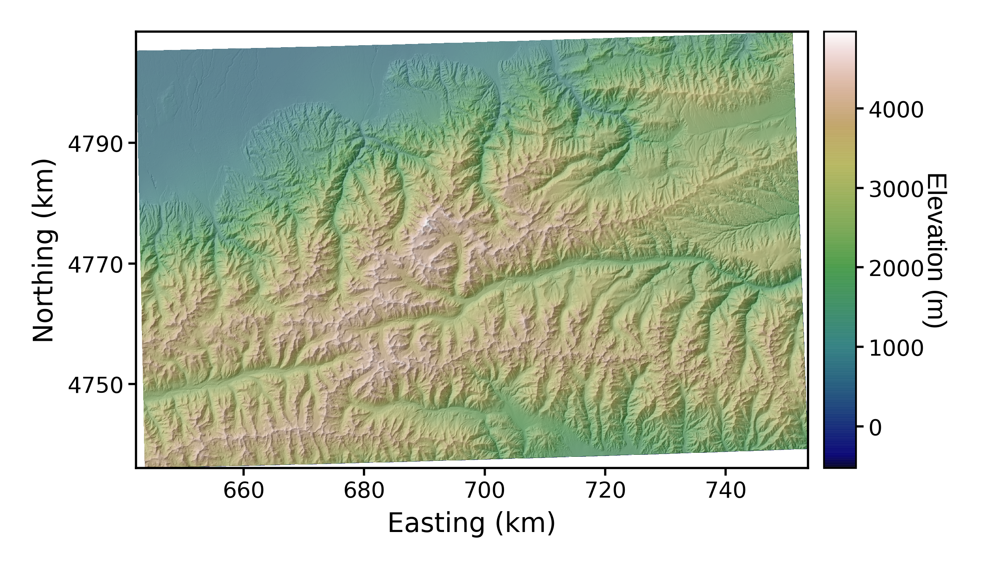

In [24]:
print(this_img)
from IPython.display import display, Image
display(Image(filename=this_img, width=800))

## Pick some basins

Use google maps to right-click near the outlets of the basins you want and copy that into the code below. *Warning* basin selection is quite sensitive and basins will not be selected if any pixel in basin is next to the DEM edge. In addition the code moves downstream from your selected basin to the next junction (an artefact due to our interest in looking at different Strahler orders) so you may have to tune the locations of the outlets quite a bit).

In [30]:
# Import pandas library
import pandas as pd

data = [ [43.14463148638686, 76.61153598709079],
         [43.151380802820015, 76.79884516144782],
         [43.108139612730156, 76.90936034698746],
         [43.106675216444756, 76.92124668215702],
         [43.24424751356771, 77.21871828721397],
         [43.30569169893644, 77.49804718479781]]

# Create the pandas DataFrame
df = pd.DataFrame(data, columns = ['latitude', 'longitude'])

df.to_csv("basin_outlets.csv",index=False)
df.head()

,latitude,longitude
0,43.144631,76.611536
1,43.151381,76.798845
2,43.108140,76.909360
3,43.106675,76.921247
4,43.244248,77.218718


In [34]:
import lsdviztools.lsdmapwrappers as lsdmw

## Get the basins
lsdtt_parameters = {"print_basin_raster" : "true",
                    "get_basins_from_outlets" : "true",
                    "basin_outlet_csv" : "basin_outlets.csv",
                    "print_chi_data_maps" : "true"}
lsdtt_drive = lsdmw.lsdtt_driver(command_line_tool = "lsdtt-chi-mapping",
                                 read_prefix = r_prefix,
                                 write_prefix= w_prefix,
                                 read_path = "./",
                                 write_path = "./",
                                 parameter_dictionary=lsdtt_parameters)
lsdtt_drive.print_parameters()
lsdtt_drive.run_lsdtt_command_line_tool()

The lsdtopotools command line tools available are: 
['lsdtt-basic-metrics', 'lsdtt-channel-extraction', 'lsdtt-chi-mapping', 'lsdtt-cosmo-tool', 'lsdtt-hillslope-channel-coupling', 'lsdtt-valley-metrics', 'lsdtt-basin-metrics']
Testing has been done against lsdtopotools v0.7
The command line tool is: lsdtt-chi-mapping
The driver name is: Test_01
The read path is: ./
The write path is: ./
The read prefix is: copernicus_dem_glo30_clip
The write prefix is: copernicus_dem_glo30_clip
The parameter dictionary is:
{'print_basin_raster': 'true', 'get_basins_from_outlets': 'true', 'basin_outlet_csv': 'basin_outlets.csv', 'print_chi_data_maps': 'true'}
Done writing the driver file
I've finished writing the driver file. Let me run LSDTT for you.


In [32]:
# uncomment this for debugging
#import lsdviztools.lsdmapwrappers as lsdmw
DataDirectory = "./"
Base_file = r_prefix

#%%capture
basins_img = lsdmw.PrintBasins_Complex(DataDirectory,Base_file,cmap="gist_earth",
                             size_format="geomorphology",dpi=600, save_fig = True)

Basin keys are: 
[0, 1, 2, 3]
I'm going to make the basin plots. Your topographic data must be in ENVI bil format or I'll break!!
Your colourbar will be located: None
xsize: 3718 and y size: 2414
NoData is: -9999.0
Yoyoyoyo the EPSG is :EPSG:32643
EPSG:32643
The EPSGString is: EPSG:32643
minimum values are x: 642123.0 and y: 4736044.0
I made the ticks.
x labels are: 
['660', '680', '700', '720', '740']
x locations are:
[np.float64(660000.0), np.float64(680000.0), np.float64(700000.0), np.float64(720000.0), np.float64(740000.0)]
y labels are: 
['4750', '4770', '4790']
y locations are:
[np.float64(4750000.0), np.float64(4770000.0), np.float64(4790000.0)]
This colourmap is: gray


/usr/local/lib/python3.12/dist-packages/lsdviztools/lsdmapfigure/plottingraster.py:456: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(self.tick_x_labels)
/usr/local/lib/python3.12/dist-packages/lsdviztools/lsdmapfigure/plottingraster.py:457: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(self.tick_y_labels)


The number of axes are: 1
Axes(0,0;1x1)
Axes(0,0;1x1)
Welcome to the basin plotting subroutine. I will plot some basins for you
This version does not rely on descartes
copernicus_dem_glo30_clip_AllBasins.bil
Let me grab the coordinate reference system.
EPSG:32643
Whoops. Found a repeated ID. Getting rid of the smaller one.
Keeping the initial ID.
Whoops. Found a repeated ID. Getting rid of the smaller one.
Found a repeated ID. Keeping the one with area of 83738700.0
I need to convert the crs to wkt format so it is resistant to stupid proj errors.
ID is: 2330.0
ID is: 757.0
ID is: 1184.0
ID is: 2219.0
The number of basins are: 4
The number of points are: 4
Plotting the polygons, colouring by basin...I am using the geopandas version
2330.0 2330
757.0 757
1184.0 1184
2219.0 2219
The aspect ratio is: 1.540182270091135
I need to adjust the spacing of the colourbar.
The cbar characters are: 0 and the cbar text width is: 0.4
No colourbar
The figure size is: 
[6.25, 4.226223776223776]
Map axes

./copernicus_dem_glo30_clip_selected_basins.png


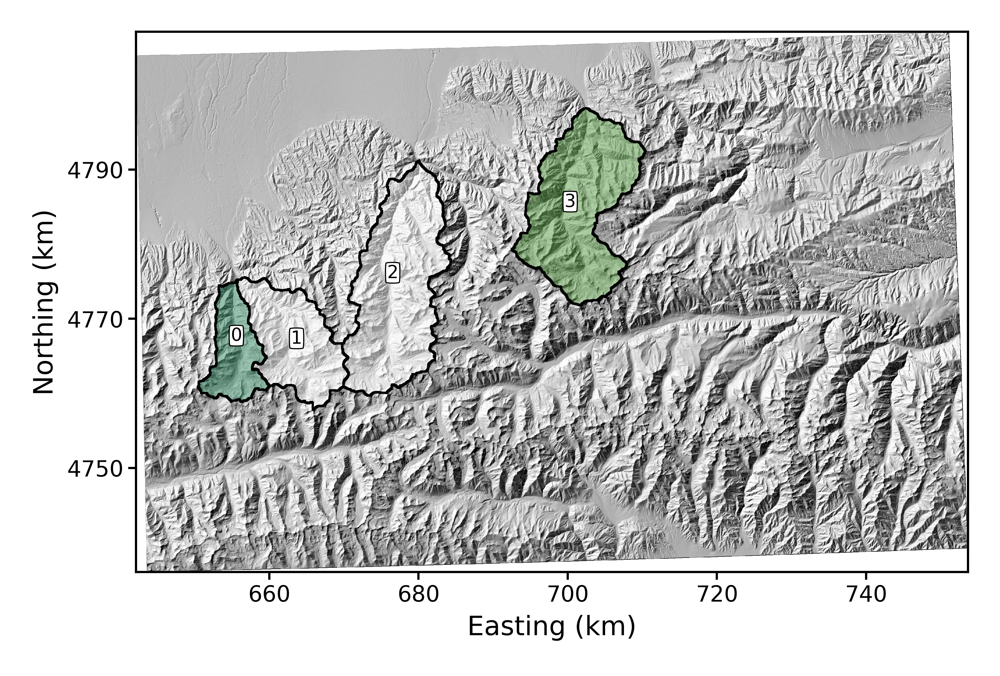

In [33]:
print(basins_img)
from IPython.display import display, Image
display(Image(filename=basins_img, width=800))

In [36]:
import lsdviztools.lsdmapwrappers as lsdmw

## Get the basins
lsdtt_parameters = {"m_over_n" : "0.45",
                    "print_segmented_M_chi_map_to_csv" : "true",
                    "get_basins_from_outlets" : "true",
                    "basin_outlet_csv" : "basin_outlets.csv"}
lsdtt_drive = lsdmw.lsdtt_driver(command_line_tool = "lsdtt-chi-mapping",
                                 read_prefix = r_prefix,
                                 write_prefix= w_prefix,
                                 read_path = "./",
                                 write_path = "./",
                                 parameter_dictionary=lsdtt_parameters)
lsdtt_drive.print_parameters()
lsdtt_drive.run_lsdtt_command_line_tool()

The lsdtopotools command line tools available are: 
['lsdtt-basic-metrics', 'lsdtt-channel-extraction', 'lsdtt-chi-mapping', 'lsdtt-cosmo-tool', 'lsdtt-hillslope-channel-coupling', 'lsdtt-valley-metrics', 'lsdtt-basin-metrics']
Testing has been done against lsdtopotools v0.7
The command line tool is: lsdtt-chi-mapping
The driver name is: Test_01
The read path is: ./
The write path is: ./
The read prefix is: copernicus_dem_glo30_clip
The write prefix is: copernicus_dem_glo30_clip
The parameter dictionary is:
{'m_over_n': '0.45', 'print_segmented_M_chi_map_to_csv': 'true', 'get_basins_from_outlets': 'true', 'basin_outlet_csv': 'basin_outlets.csv'}
Done writing the driver file
I've finished writing the driver file. Let me run LSDTT for you.


In [39]:
!lsdtt_plotchianalysis -dir . -fname copernicus_dem_glo30_clip -all_stacks true -basin_lists "0,1,2,3"

You forgot the separator at the end of the directory, appending...
Let me check if there is a basins info csv file.
There is a basins info csv file
Hey pardner, I'm a gonna parse a string into a list. Yeehaw.
No items found, I am returning and empty list.
No rename dictionary found. I will return and empty dict.
The parsed dict is: 
{}
This list of lists is: 
[[0, 1, 2, 3]]
Hey pardner, I'm a gonna parse a string into a list. Yeehaw.
No items found, I am returning and empty list.
Hey pardner, I'm a gonna parse a string into a list. Yeehaw.
No items found, I am returning and empty list.
All basins are: 
[0, 1, 2, 3]
The basins to keep are:
[0, 1, 2, 3]
The basins to mask are:
[]
The number of stacks are: 1
{0: 0.0, 1: 0.0, 2: 0.0, 3: 0.0}
Initial offsets are: 
[5]
And const offset is: 5
Final offset is: 
[5]
Initial offsets are: 
[20000]
And const offset is: 20000
Final offset is: 
[20000]
I am going to plot some chi stacks for you.
[[0, 1, 2, 3]]
Basin keys are: 
[0, 1, 2, 3]
About to 

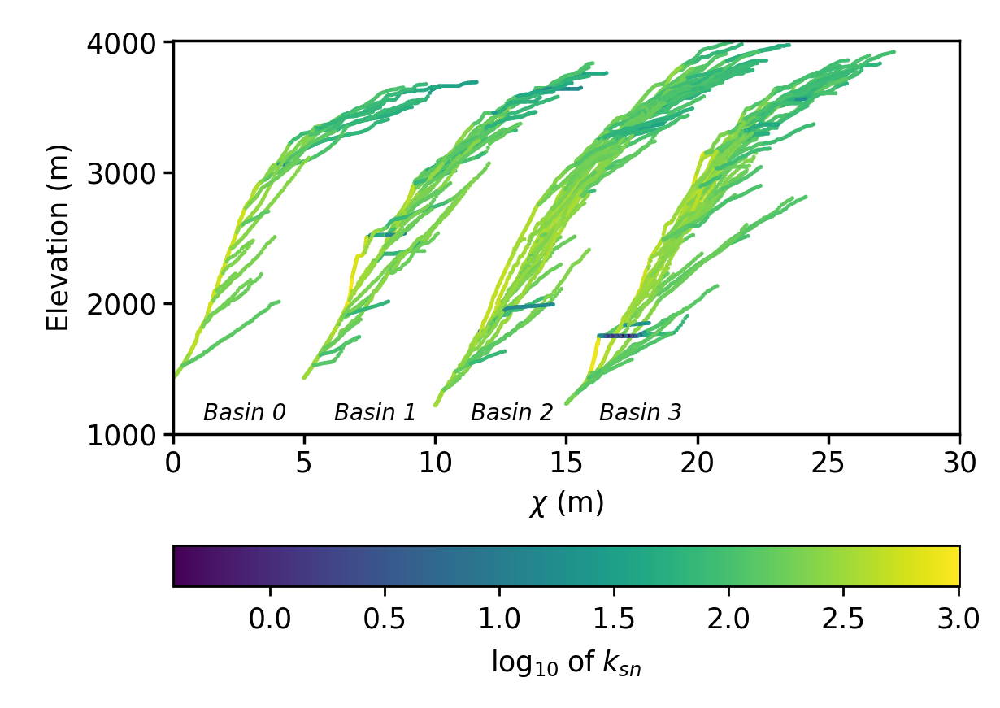

In [40]:
from IPython.display import display, Image
display(Image(filename="./chi_profile_plots/Stacked_1_chi_stacked_chi.png", width=800))